Dataset shape:      (3288, 17)
Care groups:        <StringArray>
['ERWACHSENE', 'NICU', 'PICU']
Length: 3, dtype: str
Date range:         2023-02-10 → 2026-02-09
Total observations: 3288

OBSERVATION COUNT PER CARE GROUP
care_group
ERWACHSENE    1096
NICU          1096
PICU          1096

DESCRIPTIVE STATISTICS — FULL DATASET (ALL CARE GROUPS)
           reporting_units  icu_beds_occupied  icu_beds_available  total_icu_capacity  utilization_rate  slack_rate  staff_constraints  space_constraints  material_constraints  staff_rate  space_rate  material_rate
count            3288.0000          3288.0000           3288.0000           3288.0000         3288.0000   3288.0000          3288.0000          3288.0000             3288.0000   3288.0000   3288.0000      3288.0000
mean              430.1125          4825.4288           1004.2266           5829.6554            0.7155      0.2845           132.4842            44.4465                1.0103      0.2647      0.0903         0.0043
std      

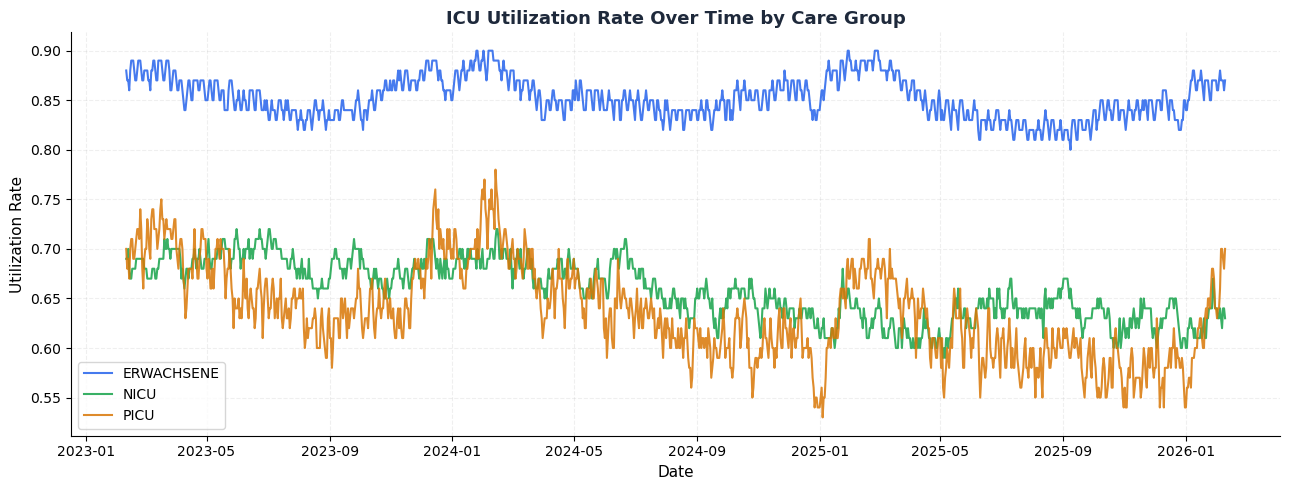

📊 Saved → desc_utilization_over_time.png


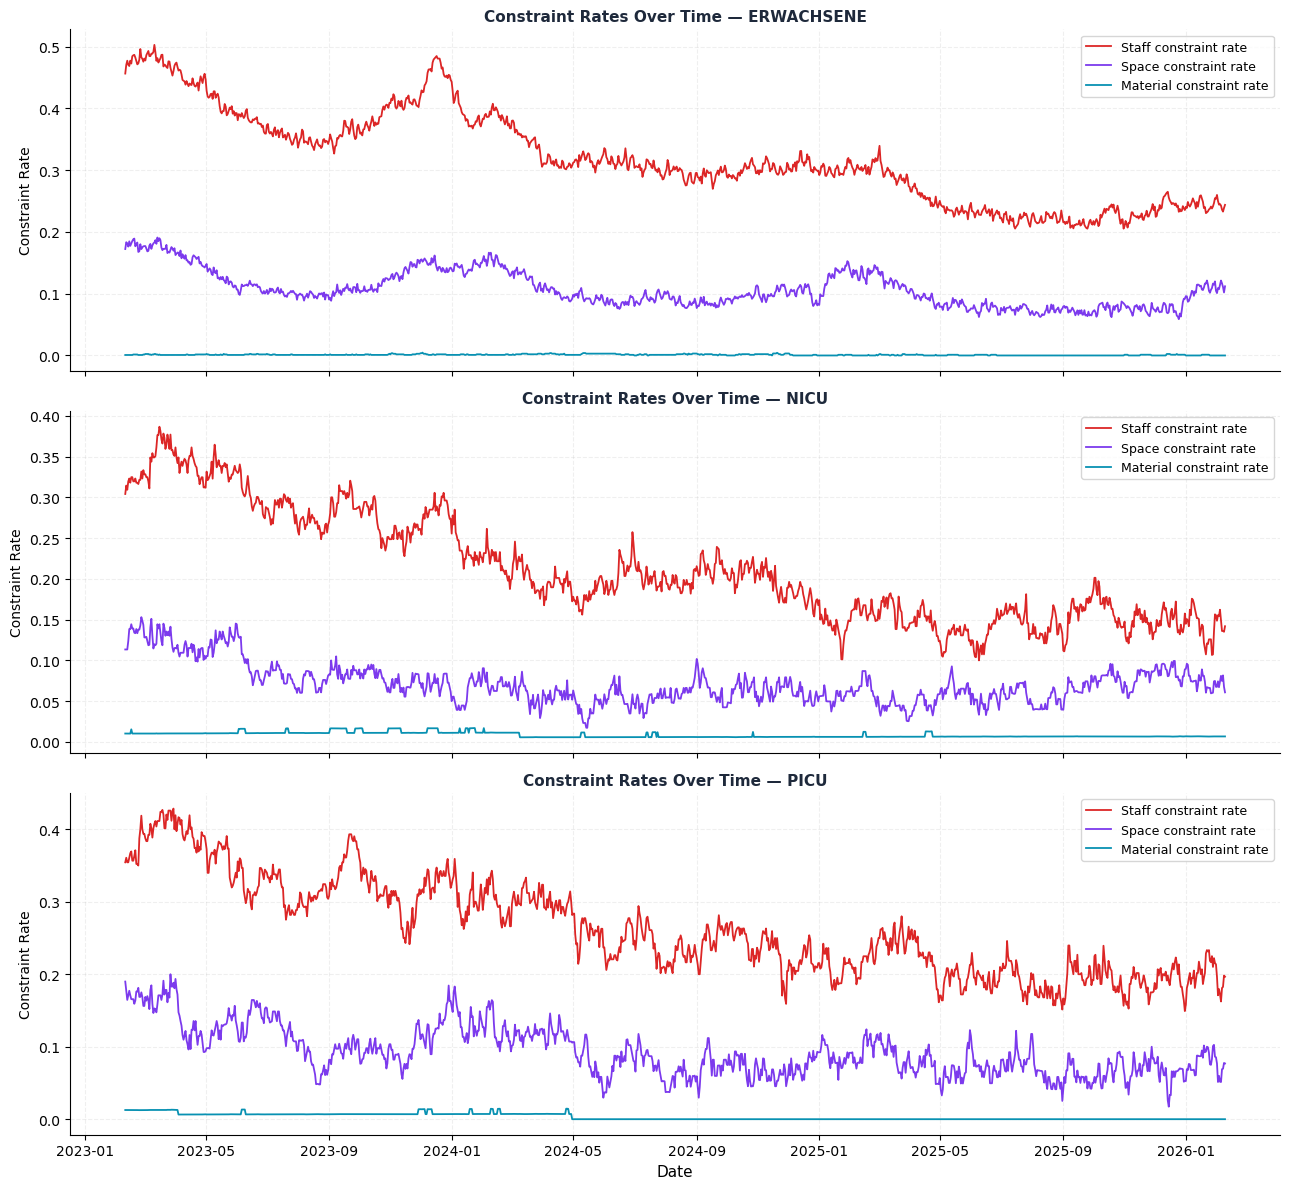

📊 Saved → desc_constraint_rates_over_time.png


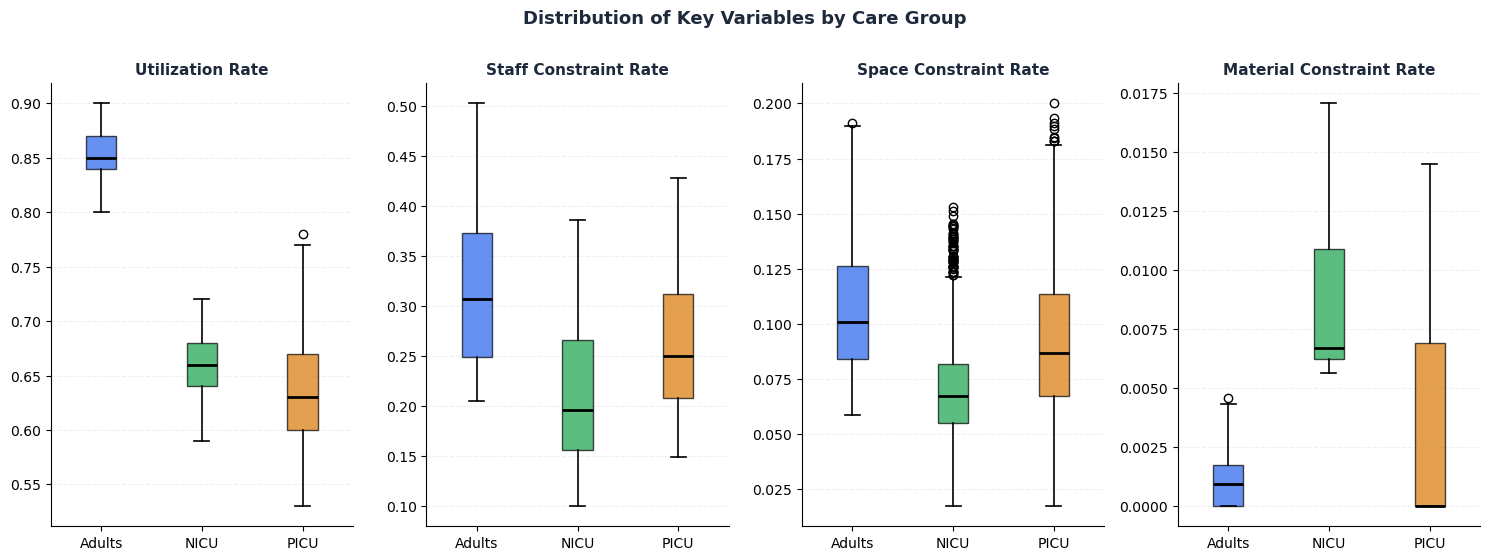

📊 Saved → desc_boxplots_by_group.png


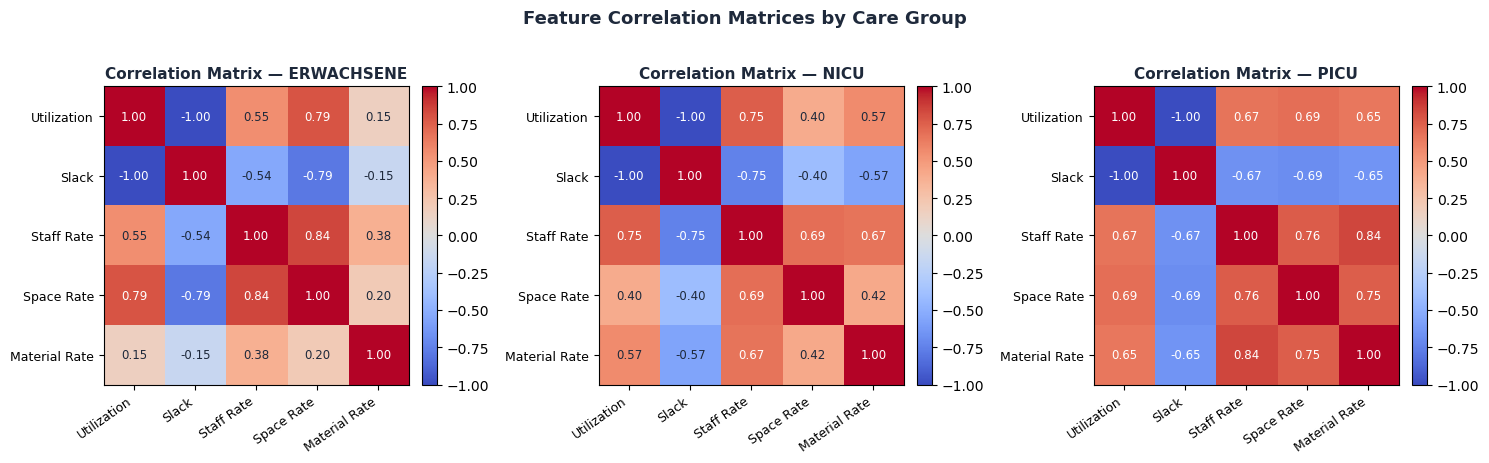

📊 Saved → desc_correlation_heatmaps.png

✅ All descriptive statistics complete.


In [1]:
"""
Descriptive Statistics — DIVI-Intensivregister
Germany ICU Capacity Dataset
Thesis: Mapping ICU Capacity Strain in Germany — Sarah Busch
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────
# 1. LOAD & CLEAN
# ─────────────────────────────────────────

DATA_PATH = "Intensivregister_updated.csv"

df = pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')
df.columns = df.columns.str.strip()

for col in df.columns:
    if col not in ['date', 'care_group']:
        df[col] = (
            df[col].astype(str)
                   .str.replace(',', '.', regex=False)
                   .str.strip()
        )
        df[col] = pd.to_numeric(df[col], errors='coerce')

df['date'] = pd.to_datetime(df['date'], dayfirst=True)

# Engineer constraint rates
df['staff_rate']    = df['staff_constraints']    / df['reporting_units']
df['space_rate']    = df['space_constraints']    / df['reporting_units']
df['material_rate'] = df['material_constraints'] / df['reporting_units']

# Drop COVID columns
covid_cols = [c for c in df.columns if 'covid' in c.lower()]
df = df.drop(columns=covid_cols, errors='ignore')

print(f"Dataset shape:      {df.shape}")
print(f"Care groups:        {df['care_group'].unique()}")
print(f"Date range:         {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Total observations: {len(df)}\n")

# ─────────────────────────────────────────
# 2. OVERVIEW PER CARE GROUP
# ─────────────────────────────────────────

print("=" * 60)
print("OBSERVATION COUNT PER CARE GROUP")
print("=" * 60)
counts = df.groupby('care_group').size().rename('n_observations')
print(counts.to_string())

# ─────────────────────────────────────────
# 3. FULL DESCRIPTIVE STATISTICS
# ─────────────────────────────────────────

analysis_vars = [
    'reporting_units',
    'icu_beds_occupied',
    'icu_beds_available',
    'total_icu_capacity',
    'utilization_rate',
    'slack_rate',
    'staff_constraints',
    'space_constraints',
    'material_constraints',
    'staff_rate',
    'space_rate',
    'material_rate',
]

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS — FULL DATASET (ALL CARE GROUPS)")
print("=" * 60)
desc_all = df[analysis_vars].describe().round(4)
desc_all.loc['median'] = df[analysis_vars].median().round(4)
desc_all.loc['skewness'] = df[analysis_vars].skew().round(4)
desc_all.loc['missing'] = df[analysis_vars].isnull().sum()
desc_all.loc['missing_%'] = (df[analysis_vars].isnull().mean() * 100).round(2)
print(desc_all.to_string())

# ─────────────────────────────────────────
# 4. DESCRIPTIVE STATISTICS BY CARE GROUP
# ─────────────────────────────────────────

for group in ['ERWACHSENE', 'NICU', 'PICU']:
    subset = df[df['care_group'] == group]
    print(f"\n{'=' * 60}")
    print(f"DESCRIPTIVE STATISTICS — {group}  (n = {len(subset)})")
    print(f"{'=' * 60}")
    desc = subset[analysis_vars].describe().round(4)
    desc.loc['median']    = subset[analysis_vars].median().round(4)
    desc.loc['skewness']  = subset[analysis_vars].skew().round(4)
    desc.loc['missing']   = subset[analysis_vars].isnull().sum()
    desc.loc['missing_%'] = (subset[analysis_vars].isnull().mean() * 100).round(2)
    print(desc.to_string())

# ─────────────────────────────────────────
# 5. SAVE DESCRIPTIVE STATS TO CSV
# ─────────────────────────────────────────

# Full dataset
desc_all.to_csv("descriptive_stats_all.csv")

# Per care group
for group in ['ERWACHSENE', 'NICU', 'PICU']:
    subset = df[df['care_group'] == group]
    desc = subset[analysis_vars].describe().round(4)
    desc.loc['median']    = subset[analysis_vars].median().round(4)
    desc.loc['skewness']  = subset[analysis_vars].skew().round(4)
    desc.loc['missing']   = subset[analysis_vars].isnull().sum()
    desc.loc['missing_%'] = (subset[analysis_vars].isnull().mean() * 100).round(2)
    desc.to_csv(f"descriptive_stats_{group.lower()}.csv")

print("\n💾 CSV files saved:")
print("   descriptive_stats_all.csv")
print("   descriptive_stats_erwachsene.csv")
print("   descriptive_stats_nicu.csv")
print("   descriptive_stats_picu.csv")

# ─────────────────────────────────────────
# 6. VISUALISATIONS
# ─────────────────────────────────────────

COLORS   = {'ERWACHSENE': '#2563EB', 'NICU': '#16a34a', 'PICU': '#d97706'}
DARK     = '#1e293b'

# ── 6a. Utilization rate over time by care group ──
fig, ax = plt.subplots(figsize=(13, 5))
for group, color in COLORS.items():
    subset = df[df['care_group'] == group].sort_values('date')
    ax.plot(subset['date'], subset['utilization_rate'],
            label=group, color=color, linewidth=1.5, alpha=0.85)
ax.set_title('ICU Utilization Rate Over Time by Care Group',
             fontsize=13, fontweight='bold', color=DARK)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylabel('Utilization Rate', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2, linestyle='--')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('desc_utilization_over_time.png', dpi=180, bbox_inches='tight')
plt.show()
print("📊 Saved → desc_utilization_over_time.png")

# ── 6b. Constraint rates over time (3 panels, one per care group) ──
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, (group, color) in zip(axes, COLORS.items()):
    subset = df[df['care_group'] == group].sort_values('date')
    ax.plot(subset['date'], subset['staff_rate'],
            label='Staff constraint rate', color='#dc2626', linewidth=1.3)
    ax.plot(subset['date'], subset['space_rate'],
            label='Space constraint rate', color='#7c3aed', linewidth=1.3)
    ax.plot(subset['date'], subset['material_rate'],
            label='Material constraint rate', color='#0891b2', linewidth=1.3)
    ax.set_title(f'Constraint Rates Over Time — {group}',
                 fontsize=11, fontweight='bold', color=DARK)
    ax.set_ylabel('Constraint Rate', fontsize=10)
    ax.legend(fontsize=9, loc='upper right')
    ax.grid(True, alpha=0.2, linestyle='--')
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].set_xlabel('Date', fontsize=11)
plt.tight_layout()
plt.savefig('desc_constraint_rates_over_time.png', dpi=180, bbox_inches='tight')
plt.show()
print("📊 Saved → desc_constraint_rates_over_time.png")

# ── 6c. Box plots — utilization and constraint rates by care group ──
fig, axes = plt.subplots(1, 4, figsize=(15, 5.5))
plot_vars  = ['utilization_rate', 'staff_rate', 'space_rate', 'material_rate']
plot_titles = ['Utilization Rate', 'Staff Constraint Rate',
               'Space Constraint Rate', 'Material Constraint Rate']

for ax, var, title in zip(axes, plot_vars, plot_titles):
    data_by_group = [df[df['care_group'] == g][var].dropna()
                     for g in ['ERWACHSENE', 'NICU', 'PICU']]
    bp = ax.boxplot(data_by_group, patch_artist=True,
                    medianprops=dict(color='black', linewidth=2),
                    whiskerprops=dict(linewidth=1.2),
                    capprops=dict(linewidth=1.2))
    for patch, color in zip(bp['boxes'], COLORS.values()):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['Adults', 'NICU', 'PICU'], fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold', color=DARK)
    ax.grid(True, alpha=0.2, linestyle='--', axis='y')
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Distribution of Key Variables by Care Group',
             fontsize=13, fontweight='bold', color=DARK, y=1.01)
plt.tight_layout()
plt.savefig('desc_boxplots_by_group.png', dpi=180, bbox_inches='tight')
plt.show()
print("📊 Saved → desc_boxplots_by_group.png")

# ── 6d. Correlation heatmap (all groups combined) ──
import matplotlib.colors as mcolors

corr_vars = ['utilization_rate', 'slack_rate',
             'staff_rate', 'space_rate', 'material_rate']
corr_labels = ['Utilization', 'Slack', 'Staff Rate', 'Space Rate', 'Material Rate']

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (group, color) in zip(axes, COLORS.items()):
    subset = df[df['care_group'] == group][corr_vars].dropna()
    corr   = subset.corr().round(2)
    im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(corr_labels)))
    ax.set_yticks(range(len(corr_labels)))
    ax.set_xticklabels(corr_labels, rotation=35, ha='right', fontsize=9)
    ax.set_yticklabels(corr_labels, fontsize=9)
    ax.set_title(f'Correlation Matrix — {group}',
                 fontsize=11, fontweight='bold', color=DARK)
    for i in range(len(corr_labels)):
        for j in range(len(corr_labels)):
            ax.text(j, i, f'{corr.iloc[i, j]:.2f}',
                    ha='center', va='center', fontsize=8.5,
                    color='white' if abs(corr.iloc[i, j]) > 0.6 else DARK)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Feature Correlation Matrices by Care Group',
             fontsize=13, fontweight='bold', color=DARK, y=1.02)
plt.tight_layout()
plt.savefig('desc_correlation_heatmaps.png', dpi=180, bbox_inches='tight')
plt.show()
print("📊 Saved → desc_correlation_heatmaps.png")

print("\n" + "=" * 60)
print("✅ All descriptive statistics complete.")
print("=" * 60)